EDA Assignment: Does More Health Spending = Longer Life?
**Name:** ___________________  |  **Date:** __________  |  ⏱️ *Target time: ~1 hour*

---
### 🤔 The big question
Every country spends money on healthcare — some spend *a lot* more than others. It seems obvious that **spending more should mean people live longer**... right?

**Your job:** use EDA to find out if that's actually true. This is an **open-ended** assignment — there's no single "correct" cell to fill in. You explore the data, follow what's interesting, and back up your answer with charts.

> 🎯 **Before you touch the data, write your gut guess here:**
> *Do you think the country that spends the MOST on healthcare also lives the longest? (yes / no / not sure):* Yes

**The dataset:** health spending per person vs life expectancy, for 6 wealthy countries, 1970–2020 (real OECD-style data, built into seaborn — loads offline).

### 📤 What to hand in
Answer every ✍️ **question** in your own words, and make sure your charts are clear (titles + labels). Marks reward **insight and evidence**, not fancy code. Run *Kernel → Restart & Run All* before submitting.

## Step 0 — Setup & Load *(warm-up)*

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = sns.load_dataset('healthexp')   # Year, Country, Spending_USD, Life_Expectancy
print("Shape:", df.shape)
df.head()

Shape: (274, 4)


,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [ ]:
# TODO: Get to know the data. Show:
#   - which countries are included  (HINT: df['Country'].unique())
#   - the range of years            (HINT: df['Year'].min(), df['Year'].max())
#   - a quick df.describe()

In [ ]:
print(df['Country'].unique(),"\n")
print(df['Year'].min(), "\n")
print(df['Year'].max(), "\n")
print(df.describe(), "\n")

['Germany' 'France' 'Great Britain' 'Japan' 'USA' 'Canada'] 

1970 

2020 

              Year  Spending_USD  Life_Expectancy
count   274.000000    274.000000       274.000000
mean   1996.992701   2789.338905        77.909489
std      14.180933   2194.939785         3.276263
min    1970.000000    123.993000        70.600000
25%    1985.250000   1038.357000        75.525000
50%    1998.000000   2295.578000        78.100000
75%    2009.000000   4055.610000        80.575000
max    2020.000000  11859.179000        84.700000 



## Task 1 — The Core Relationship *(≈15 min)*
*Is there a link between how much a country spends and how long people live?*

<Axes: xlabel='Spending_USD', ylabel='Life_Expectancy'>

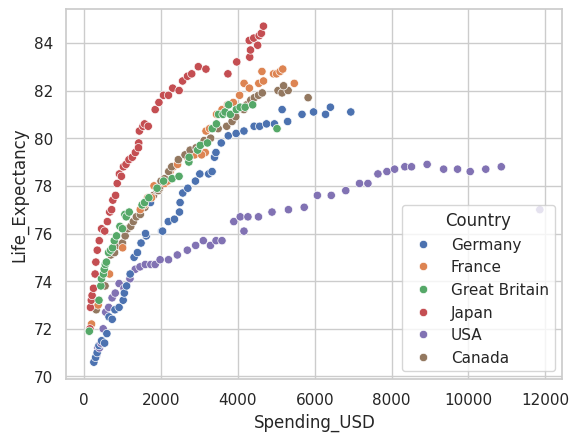

In [ ]:
# TODO: Make a scatter plot of Spending_USD (x) vs Life_Expectancy (y).
# Colour the points by Country so you can see who's who.
# HINT: sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')

sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')

**✍️ Q1:** In general, as spending goes up, does life expectancy go up, down, or stay flat? Would you call the relationship strong or weak?
*Your answer:* As spending goes up, life expectancy goes up. The relationship is strong.

*Optional hint for evidence:* `df['Spending_USD'].corr(df['Life_Expectancy'])` gives a number from −1 to +1.

## Task 2 — Find the Odd One Out *(≈15 min)*
*Every good analyst looks for what breaks the pattern.*

           Country  Spending_USD  Life_Expectancy
273            USA     11859.179             77.0
269        Germany      6938.983             81.1
268         Canada      5828.324             81.7
270         France      5468.418             82.3
271  Great Britain      5018.700             80.4
272          Japan      4665.641             84.7


<Axes: xlabel='Country', ylabel='Spending_USD'>

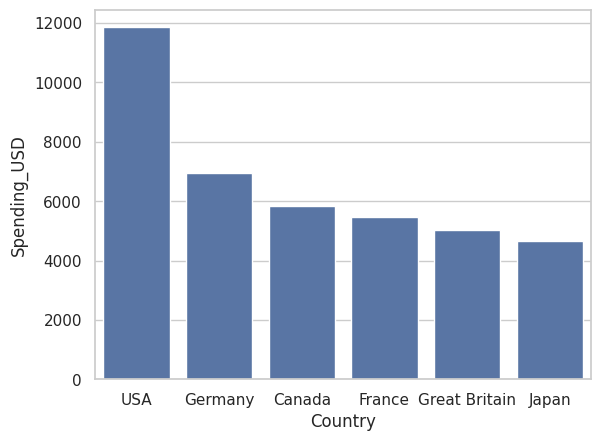

In [ ]:
# TODO: Look at just the most recent year in the data.
# HINT: latest = df[df['Year'] == df['Year'].max()]
latest = df[df['Year'] == df['Year'].max()]

# Then sort by Spending_USD to see who spends the most vs who lives longest.
sorted_data = latest.sort_values(by='Spending_USD', ascending=False)

# A bar chart of spending per country (for that year) makes it obvious.
print(sorted_data[['Country', 'Spending_USD', 'Life_Expectancy']])
sns.barplot(data=sorted_data, x='Country', y='Spending_USD')


**✍️ Q2:** Which country **spends the most** per person? Which country **lives the longest**? Are they the same country? *(This is the heart of the assignment — what surprised you?)*
*Your answer:* The USA spends the most per person while Japan lives the longest, surprisingly revealing that the highest spending country actually has the lowest life expectancy.

## Task 3 — Change Over Time *(≈15 min)*
*Has the story always been this way, or did it change?*

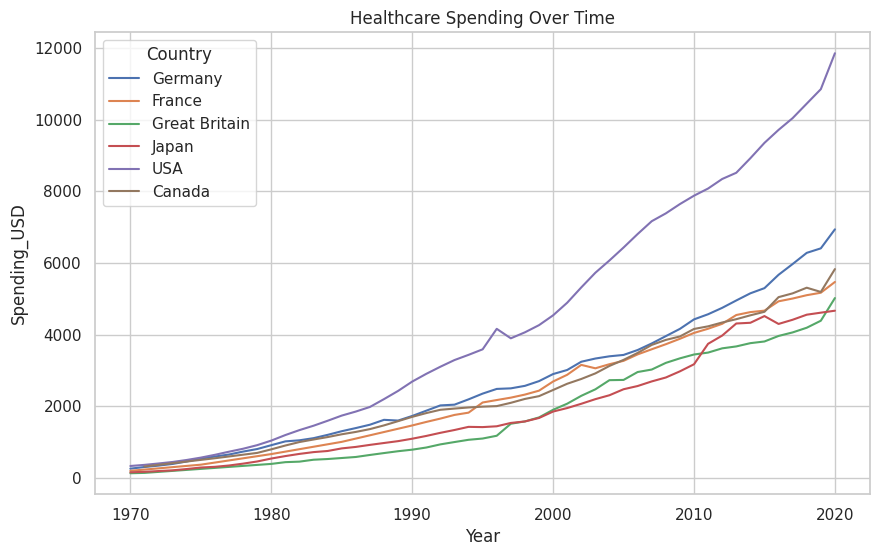

In [ ]:
# TODO: Plot how ONE thing changed from 1970 to 2020, for every country.
# Pick either Spending_USD OR Life_Expectancy over Year, with one line per country.
# HINT: sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')
plt.title('Healthcare Spending Over Time')
plt.show()


**✍️ Q3:** Describe one clear trend you see over time. Does one country pull away from the others at some point?
*Your answer:* Healthcare spending increases steadily for all countries over time, with the USA dramatically pulling away from the rest of the group to spend at a much steeper rate.

## Task 4 — Your Own Investigation *(≈10 min)*  🔍 *open-ended*
Ask **your own** question about this data and answer it with **one** chart. Ideas (or invent your own):
- Who improved their life expectancy the *most* since 1970?
- Which country gets the most "life expectancy per dollar" (best value)?
- Is any country's life expectancy *flattening* even as spending climbs?

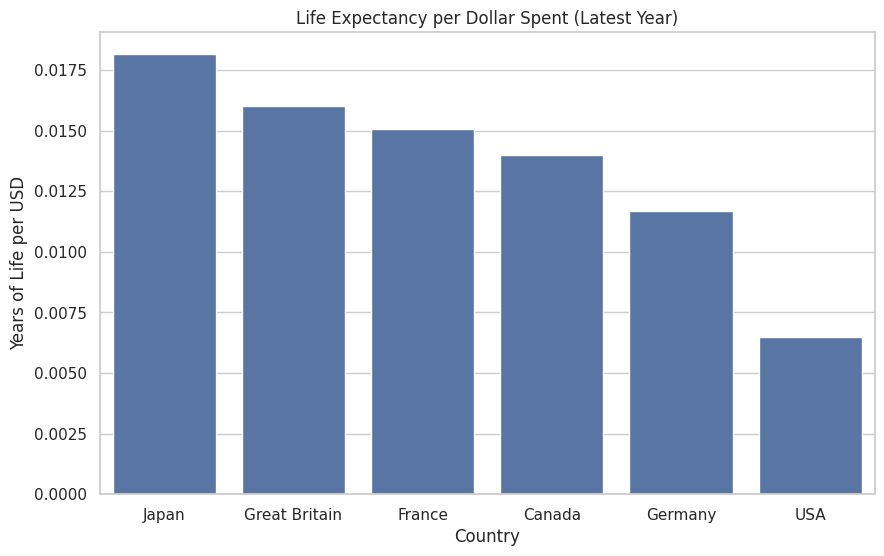

In [ ]:
# TODO: Your question, your chart. Write your question as a comment first, then the code.
# My question: ...
latest = df[df['Year'] == df['Year'].max()].copy()
latest['Value'] = latest['Life_Expectancy'] / latest['Spending_USD']
latest_sorted = latest.sort_values(by='Value', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=latest_sorted, x='Country', y='Value')
plt.title('Life Expectancy per Dollar Spent (Latest Year)')
plt.ylabel('Years of Life per USD')
plt.show()


**✍️ Q4:** What did *your* chart show? State your finding in one sentence.
*Your answer:* The chart showed that Japan gets the most "life expectancy per dollar" spent, while the USA receives the lowest value for its healthcare spending.

## 🏁 Your Verdict
Answer the assignment's big question in **2–3 sentences**, using what your charts showed. Then look back: **was your gut guess from the top right or wrong?**

**✍️ Final verdict:**

> _______________________________________________
>
> _______________________________________________

> *My original guess was (right / wrong) because: I assumed the country spending the most money per person would naturally have the highest life expectancy, but the USA's extreme spending coupled with its lower life expectancy completely contradicted this assumption.

---
✅ *Before submitting:* every ✍️ answered, charts have titles/labels, ran Restart & Run All with no errors. Nice work! 🎉